# 1960 — ADALINE and the Delta (LMS) Rule

**Paper:** Bernard Widrow & Marcian Hoff, *"Adaptive Switching Circuits"* (1960).

ADALINE (**ADA**ptive **LI**near **NE**uron) looks like a perceptron, but learns from the **linear output before the threshold**. It minimises the squared error by gradient descent:

$$L(w) = \tfrac12 \sum_i (y_i - w^\top x_i)^2, \qquad w \leftarrow w + \eta\,(y_i - w^\top x_i)\,x_i$$

This **Least Mean Squares (LMS) / delta rule** is the first use of gradient descent on a loss for a neuron — the direct ancestor of backpropagation.

| | Perceptron | ADALINE |
|---|---|---|
| Update uses | thresholded output | linear output |
| Updates when | only on mistakes | always (error is continuous) |
| Non-separable data | never settles | converges to least-squares solution |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)

In [2]:
class Adaline:
    def __init__(self, n_features, lr=0.01):
        self.w = rng.normal(0, 0.01, n_features)
        self.b = 0.0
        self.lr = lr

    def net(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return np.where(self.net(X) >= 0, 1, -1)

    def fit(self, X, y, epochs=30, stochastic=True):
        losses = []
        for _ in range(epochs):
            if stochastic:                                   # online LMS, sample by sample (Widrow-Hoff)
                for i in rng.permutation(len(X)):
                    err = y[i] - self.net(X[i])
                    self.w += self.lr * err * X[i]
                    self.b += self.lr * err
            else:                                            # full-batch gradient descent
                err = y - self.net(X)
                self.w += self.lr * X.T @ err / len(X)
                self.b += self.lr * err.mean()
            losses.append(0.5 * np.mean((y - self.net(X)) ** 2))
        return losses

## Overlapping (non-separable) classes
Standardising the inputs is important for gradient descent — it makes the loss surface round.

In [3]:
n = 150
X = np.vstack([rng.normal([1.5, 1], 1.0, (n, 2)), rng.normal([-1, -1], 1.0, (n, 2))])
y = np.array([1] * n + [-1] * n)
X = (X - X.mean(0)) / X.std(0)

model = Adaline(2, lr=0.01)
losses = model.fit(X, y, epochs=30)
print("accuracy:", (model.predict(X) == y).mean())

# Compare with the closed-form least-squares solution
Xa = np.c_[X, np.ones(len(X))]
w_ls = np.linalg.lstsq(Xa, y, rcond=None)[0]
print("LMS weights:        ", np.round(np.r_[model.w, model.b], 3))
print("least-squares (exact):", np.round(w_ls, 3))

accuracy: 0.9533333333333334
LMS weights:         [0.509 0.45  0.012]
least-squares (exact): [ 0.511  0.442 -0.   ]


## Learning rate matters
Too small → slow. Too large → the loss diverges. (Full-batch GD shown for clarity.)

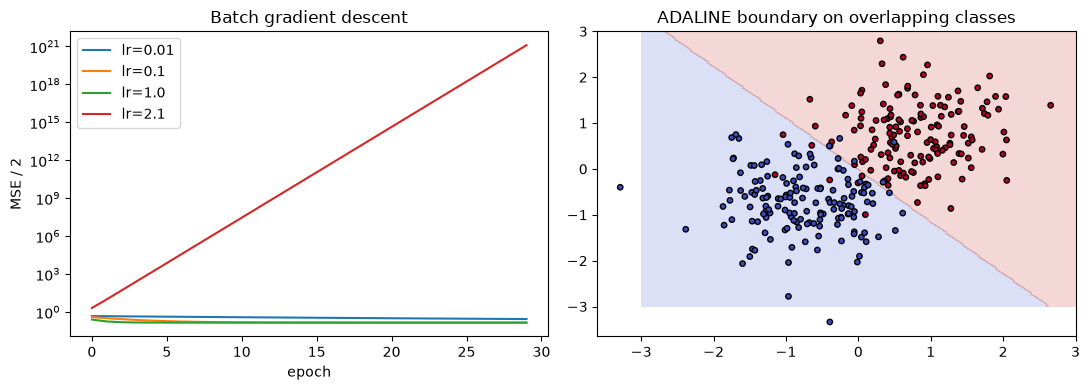

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for lr in [0.01, 0.1, 1.0, 2.1]:
    m = Adaline(2, lr=lr)
    l = m.fit(X, y, epochs=30, stochastic=False)
    axes[0].plot(l, label=f"lr={lr}")
axes[0].set(yscale="log", xlabel="epoch", ylabel="MSE / 2", title="Batch gradient descent")
axes[0].legend()

xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[1].contourf(xx, yy, zz, alpha=0.2, cmap="coolwarm")
axes[1].scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=15)
axes[1].set_title("ADALINE boundary on overlapping classes")
plt.tight_layout(); plt.show()

## Takeaways
- Define a **differentiable loss**, follow its **gradient**: the recipe for all of modern deep learning.
- Still a single linear layer, so it shares the perceptron's limits on XOR (next notebook).